In [2]:
import os

os.listdir('/content')

['.config', 'categorized_text_reviews.csv', 'sample_data']

In [3]:
import pandas as pd

df = pd.read_csv('/content/categorized_text_reviews.csv')

df.head()

,review,category
0,The product's innovative features have greatly...,Product Feedback
1,Customer service was unresponsive to my inquir...,Customer Service
2,"I was a victim of fraud, the seller requested ...",Fraud and Scam
3,The delivery was delayed due to unforeseen cir...,Operational Issues
4,"The product arrived with some defects, but the...",Product Feedback


In [4]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Category distribution
print("\nCategory Distribution:")
print(df['category'].value_counts())

Dataset Shape: (7000, 2)

Column Names:
['review', 'category']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   review    7000 non-null   object
 1   category  7000 non-null   object
dtypes: object(2)
memory usage: 109.5+ KB

Missing Values:
review      0
category    0
dtype: int64

Category Distribution:
category
Operational Issues    1800
Fraud and Scam        1755
Product Feedback      1738
Customer Service      1707
Name: count, dtype: int64


In [5]:
# Check duplicate reviews
duplicate_count = df['review'].duplicated().sum()

print("Duplicate Reviews:", duplicate_count)

# Display duplicate records
duplicates = df[df['review'].duplicated(keep=False)]

print("\nDuplicate Records:")
display(duplicates.head(10))

Duplicate Reviews: 6680

Duplicate Records:


,review,category
6,"I was scammed by a fraudulent seller, they too...",Fraud and Scam
7,I faced several issues while placing my order ...,Operational Issues
8,The product exceeded my expectations in terms ...,Product Feedback
10,Customer service was knowledgeable and provide...,Customer Service
11,"I was scammed by a fraudulent seller, they pro...",Fraud and Scam
12,"I had a great experience with the website, it ...",Operational Issues
13,The product arrived in perfect condition and m...,Product Feedback
14,Customer service was not helpful and did not p...,Customer Service
15,"I was a victim of fraud, the seller provided a...",Fraud and Scam
16,The delivery was delayed due to unforeseen cir...,Operational Issues


In [6]:
# Count unique reviews
print("Unique Reviews:", df['review'].nunique())

# Check duplicate combinations of review and category
print("Duplicate Complete Rows:", df.duplicated().sum())

# Check whether identical reviews have different categories
category_conflicts = (
    df.groupby('review')['category']
    .nunique()
)

print(
    "Reviews with conflicting categories:",
    (category_conflicts > 1).sum()
)

Unique Reviews: 320
Duplicate Complete Rows: 6680
Reviews with conflicting categories: 0


In [7]:
# Create a cleaned dataset
df_clean = df.drop_duplicates(
    subset=['review', 'category']
).copy()

# Reset index
df_clean.reset_index(drop=True, inplace=True)

# Compare original and cleaned datasets
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

print(
    "Records Removed:",
    len(df) - len(df_clean)
)

Original Dataset: (7000, 2)
Cleaned Dataset: (320, 2)
Records Removed: 6680


In [8]:
# Display all four categories
categories = df_clean['category'].unique()

for category in categories:
    print("\nCATEGORY:", category)
    print("-" * 50)

    sample = df_clean[
        df_clean['category'] == category
    ]['review'].head(3)

    for review in sample:
        print("•", review)


CATEGORY: Product Feedback
--------------------------------------------------
• The product's innovative features have greatly improved my daily tasks.
• The product arrived with some defects, but the seller was responsive and provided a replacement.
• The product exceeded my expectations in terms of quality and performance.

CATEGORY: Customer Service
--------------------------------------------------
• Customer service was unresponsive to my inquiry. I'm disappointed with the experience.
• Customer service was incredibly helpful and resolved my issue within minutes.
• Customer service was knowledgeable and provided excellent assistance throughout the purchasing process.

CATEGORY: Fraud and Scam
--------------------------------------------------
• I was a victim of fraud, the seller requested additional payment after purchase.
• I was scammed by a fraudulent seller, they took my money and never sent the product.
• I was scammed by a fraudulent seller, they provided a low-quality pro

In [9]:
# Select 40 random reviews
annotation_sample = df_clean.sample(
    n=40,
    random_state=42
).copy()

# Hide existing labels
annotation_sample = annotation_sample[['review']]

# Create annotation columns
annotation_sample['manual_label'] = ''
annotation_sample['review_status'] = 'Pending'
annotation_sample['comments'] = ''

# Save annotation file
annotation_sample.to_csv(
    'manual_annotation_task.csv',
    index=False
)

print("Annotation sample created!")
print("Total reviews:", len(annotation_sample))

display(annotation_sample.head(10))

Annotation sample created!
Total reviews: 40


,review,manual_label,review_status,comments
167,The product's design is minimalistic and elegant.,,Pending,
230,The product's features are advanced and innova...,,Pending,
25,"I was not a victim of fraud, the seller was tr...",,Pending,
63,"I was scammed, I received a product that did n...",,Pending,
9,I encountered a minor operational issue with t...,,Pending,
110,The product's design is sleek and user-friendly.,,Pending,
186,The product's design is minimalistic and sleek.,,Pending,
143,The product's performance is excellent and exc...,,Pending,
244,The product's features are advanced and cuttin...,,Pending,
224,Customer service was responsive and provided a...,,Pending,


In [10]:
from google.colab import files

files.download('manual_annotation_task.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import pandas as pd

manual_df = pd.read_csv('/content/manual_annotation_task.csv')

print("Total annotated reviews:", len(manual_df))

print("\nManual labels:")
print(manual_df['manual_label'].value_counts())

print("\nReview status:")
print(manual_df['review_status'].value_counts())

print("\nMissing values:")
print(manual_df.isnull().sum())

Total annotated reviews: 40

Manual labels:
manual_label
Product Feedback     25
Fraud and Scam        6
Customer Service      5
Operational Issue     4
Name: count, dtype: int64

Review status:
review_status
Completed    40
Name: count, dtype: int64

Missing values:
review           0
manual_label     0
review_status    0
comments         0
dtype: int64


In [12]:
# Standardise category names

manual_df['manual_label'] = manual_df['manual_label'].replace({
    'Operational Issue': 'Operational Issues'
})

print("Updated category distribution:")
print(manual_df['manual_label'].value_counts())

Updated category distribution:
manual_label
Product Feedback      25
Fraud and Scam         6
Customer Service       5
Operational Issues     4
Name: count, dtype: int64


In [13]:
# Match manual annotations with original dataset labels

comparison = manual_df.merge(
    df_clean[['review', 'category']],
    on='review',
    how='left',
    validate='one_to_one'
)

# Check whether all reviews matched
print("Total reviews:", len(comparison))

print(
    "Missing reference labels:",
    comparison['category'].isnull().sum()
)

# Compare manual and original labels
comparison['agreement'] = (
    comparison['manual_label'] == comparison['category']
)

print("\nAgreement Results:")
print(comparison['agreement'].value_counts())

# Calculate agreement percentage
agreement_percentage = (
    comparison['agreement'].mean() * 100
)

print(
    "\nAnnotation Agreement:",
    round(agreement_percentage, 2),
    "%"
)

Total reviews: 40
Missing reference labels: 0

Agreement Results:
agreement
True    40
Name: count, dtype: int64

Annotation Agreement: 100.0 %


In [14]:
from sklearn.metrics import classification_report

labels = [
    'Product Feedback',
    'Customer Service',
    'Fraud and Scam',
    'Operational Issues'
]

print(classification_report(
    comparison['category'],
    comparison['manual_label'],
    labels=labels,
    zero_division=0
))

                    precision    recall  f1-score   support

  Product Feedback       1.00      1.00      1.00        25
  Customer Service       1.00      1.00      1.00         5
    Fraud and Scam       1.00      1.00      1.00         6
Operational Issues       1.00      1.00      1.00         4

          accuracy                           1.00        40
         macro avg       1.00      1.00      1.00        40
      weighted avg       1.00      1.00      1.00        40



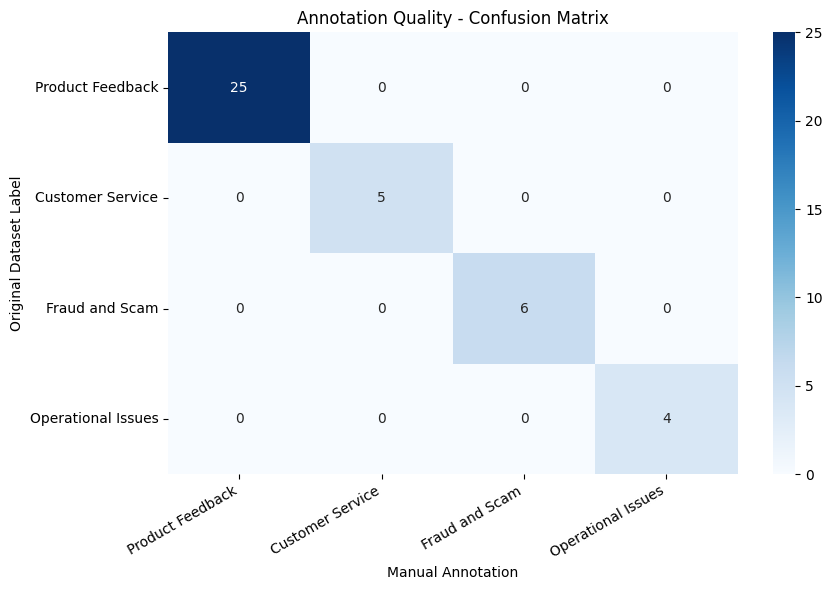

In [15]:
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

labels = [
    'Product Feedback',
    'Customer Service',
    'Fraud and Scam',
    'Operational Issues'
]

cm = confusion_matrix(
    comparison['category'],
    comparison['manual_label'],
    labels=labels
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel('Manual Annotation')
plt.ylabel('Original Dataset Label')
plt.title('Annotation Quality - Confusion Matrix')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [16]:
comparison.to_csv(
    'annotation_quality_results.csv',
    index=False
)

print("Annotation quality results saved successfully!")

Annotation quality results saved successfully!


In [17]:
df_clean.to_csv(
    'cleaned_unique_reviews.csv',
    index=False
)

print("Cleaned dataset saved successfully!")
print("Total unique reviews:", len(df_clean))

Cleaned dataset saved successfully!
Total unique reviews: 320


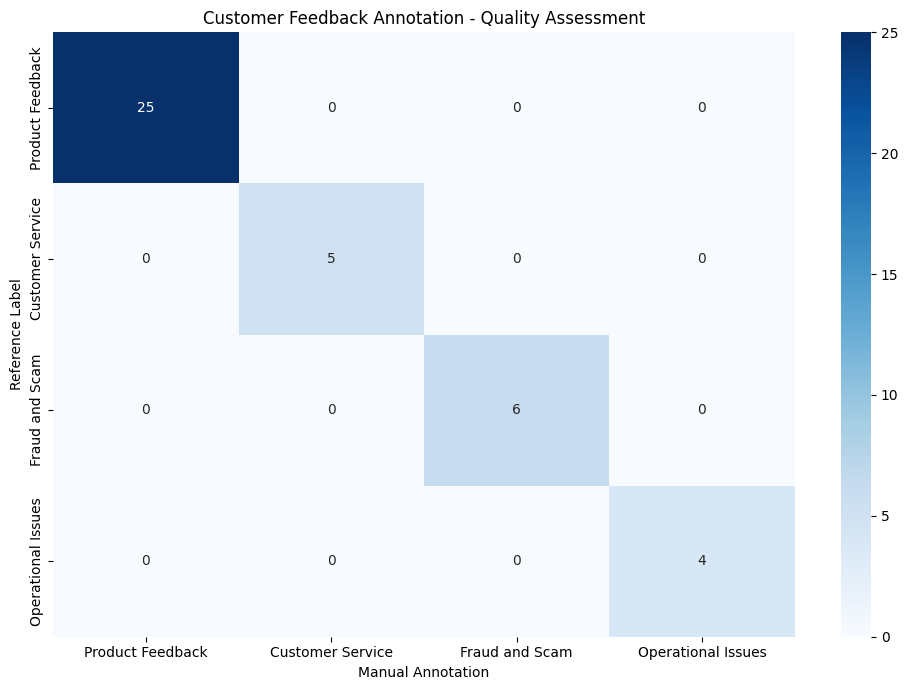

Confusion matrix saved successfully!


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = [
    'Product Feedback',
    'Customer Service',
    'Fraud and Scam',
    'Operational Issues'
]

cm = confusion_matrix(
    comparison['category'],
    comparison['manual_label'],
    labels=labels
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel('Manual Annotation')
plt.ylabel('Reference Label')
plt.title('Customer Feedback Annotation - Quality Assessment')

plt.tight_layout()

plt.savefig(
    'confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Confusion matrix saved successfully!")